# Exponentiated Gradient Reduction on Adult, German and COMPAS

Task 2 of the bias mitigation assignment. EGR (Agarwal et al., 2018) is an in-processing method, so the mitigation
happens while the model is trained. I use Fairlearn's `ExponentiatedGradient` with a demographic parity constraint
and logistic regression as the base model.

Data: `adult.data`,`adult.test`,`german.data`in the data folder provided https://archive.ics.uci.edu/dataset/2/adult
https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

COMPAS is read directly from ProPublica's GitHub.

In [7]:
%pip install -U scikit-learn fairlearn

Note: you may need to restart the kernel to use updated packages.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

eps = 0.01              #allowed demographic parity violation
seeds = [0, 1, 2, 3, 4] #5 different train/test splits
Path("results").mkdir(exist_ok=True)

## 1. Loading data

For each dataset: the label (1 = favourable outcome), the protected attribute and the privileged group.
The protected attribute is not used as a feature, EGR only gets it during training.

**Adult**: predicts income > 50K, protected attribute sex (privileged: Male). Rows with missing values are dropped, and
  `fnlwgt` and `education` (same information as `education_num`) are removed.
  
**German**: predicts good credit, protected attribute age (privileged: older than 25).

**COMPAS**: predicts not reoffending within two years, protected attribute race (privileged: Caucasian). Same filtering as ProPublica, only African-American and Caucasian defendants.

In [9]:
adult_cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
              "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
adult = pd.concat([
    pd.read_csv("data/adult.data", header=None, names=adult_cols, skipinitialspace=True, na_values="?"),
    pd.read_csv("data/adult.test", header=None, names=adult_cols, skipinitialspace=True, na_values="?", skiprows=1),
]).dropna()

y_adult = (adult["income"].str.strip(".") == ">50K").astype(int).to_numpy()
a_adult = adult["sex"].to_numpy()
X_adult = adult.drop(columns=["income", "sex", "fnlwgt", "education"])
print("Adult:", X_adult.shape)

Adult: (45222, 11)


In [10]:
german_cols = ["checking_status", "duration", "credit_history", "purpose", "credit_amount", "savings", "employment",
               "installment_rate", "personal_status_sex", "other_debtors", "residence_since", "property", "age",
               "other_installment_plans", "housing", "existing_credits", "job", "num_dependents", "telephone",
               "foreign_worker", "credit"]
german = pd.read_csv("data/german.data", sep=" ", header=None, names=german_cols)

y_german = (german["credit"] == 1).astype(int).to_numpy()   # 1 = good, 2 = bad
a_german = np.where(german["age"] > 25, "over 25", "25 or younger")
X_german = german.drop(columns=["credit", "age"])
print("German:", X_german.shape)

German: (1000, 19)


In [11]:
compas = pd.read_csv("https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv")
compas = compas[(compas["days_b_screening_arrest"] <= 30) & (compas["days_b_screening_arrest"] >= -30)
                & (compas["is_recid"] != -1) & (compas["c_charge_degree"] != "O") & (compas["score_text"] != "N/A")]
compas = compas[compas["race"].isin(["African-American", "Caucasian"])]

y_compas = (compas["two_year_recid"] == 0).astype(int).to_numpy()
a_compas = compas["race"].to_numpy()
X_compas = compas[["sex", "age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count", "c_charge_degree"]]
print("COMPAS:", X_compas.shape)

COMPAS: (5278, 7)


In [12]:
datasets = {}
for name, X, y, a, priv in [("Adult", X_adult, y_adult, a_adult, "Male"),
                            ("German", X_german, y_german, a_german, "over 25"),
                            ("COMPAS", X_compas, y_compas, a_compas, "Caucasian")]:
    num_cols = X.select_dtypes("number").columns   # numeric columns get scaled later
    X = pd.get_dummies(X, dtype=float).reset_index(drop=True)
    datasets[name] = {"X": X, "y": y, "a": a, "priv": priv, "num_cols": num_cols}

## 2. Fairness of the original labels


In [13]:
def dp_diff(y, a, priv):
    return abs(y[a != priv].mean() - y[a == priv].mean())

def di_ratio(y, a, priv):
    return y[a != priv].mean() / y[a == priv].mean()

def consistency(X, y, k=5):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    _, idx = nn.kneighbors(X)
    return 1 - np.mean(np.abs(y - y[idx].mean(axis=1)))

In [14]:
before = []
for name, d in datasets.items():
    X, y, a, priv = d["X"].copy(), d["y"], d["a"], d["priv"]
    X[d["num_cols"]] = StandardScaler().fit_transform(X[d["num_cols"]])
    before.append({"dataset": name,
                   "P(fav | unpriv)": y[a != priv].mean(),
                   "P(fav | priv)": y[a == priv].mean(),
                   "DP_Diff": dp_diff(y, a, priv),
                   "DIR": di_ratio(y, a, priv),
                   "Consistency": consistency(X.to_numpy(), y)})

before = pd.DataFrame(before).set_index("dataset")
before.round(3)

,P(fav | unpriv),P(fav | priv),DP_Diff,DIR,Consistency
dataset,,,,,
Adult,0.114,0.312,0.199,0.363,0.839
German,0.579,0.728,0.149,0.795,0.744
COMPAS,0.477,0.609,0.132,0.783,0.652


## 3–5. Split, train with EGR, evaluate on the test set

In [15]:
results = []
for name, d in datasets.items():
    X, y, a, priv, num_cols = d["X"], d["y"], d["a"], d["priv"], d["num_cols"]
    strata = [f"{label}_{group}" for label, group in zip(y, a)]

    for seed in seeds:
        X_train, X_test, y_train, y_test, a_train, a_test = train_test_split(
            X, y, a, test_size=0.3, stratify=strata, random_state=seed)
        X_train, X_test = X_train.copy(), X_test.copy()
        scaler = StandardScaler().fit(X_train[num_cols])
        X_train[num_cols] = scaler.transform(X_train[num_cols])
        X_test[num_cols] = scaler.transform(X_test[num_cols])

        lr = LogisticRegression(max_iter=2000).fit(X_train, y_train)
        pred_lr = lr.predict(X_test)

        #EGR
        egr = ExponentiatedGradient(LogisticRegression(max_iter=2000),
                                    constraints=DemographicParity(difference_bound=EPS), eps=EPS)
        egr.fit(X_train, y_train, sensitive_features=a_train)
        pred_egr = egr.predict(X_test, random_state=seed)

        #EGR with the protected attribute as an extra feature (setup of the paper)
        egr_a = ExponentiatedGradient(LogisticRegression(max_iter=2000),
                                      constraints=DemographicParity(difference_bound=EPS), eps=EPS)
        egr_a.fit(X_train.assign(protected=(a_train == priv) * 1.0), y_train, sensitive_features=a_train)
        pred_egr_a = egr_a.predict(X_test.assign(protected=(a_test == priv) * 1.0), random_state=seed)

        for model, pred in [("No mitigation", pred_lr), ("EGR", pred_egr), ("EGR, A as feature", pred_egr_a)]:
            results.append({"dataset": name, "seed": seed, "model": model,
                            "DP_Diff": dp_diff(pred, a_test, priv),
                            "DIR": di_ratio(pred, a_test, priv),
                            "Consistency": consistency(X_test.to_numpy(), pred),
                            "Accuracy": accuracy_score(y_test, pred),
                            "Balanced accuracy": balanced_accuracy_score(y_test, pred)})
    print(name, "done")

results = pd.DataFrame(results)

Adult done
German done
COMPAS done


Mean over the 5 splits:

In [16]:
mean = results.groupby(["dataset", "model"], sort=False).mean().drop(columns="seed")
mean.round(3)

DP_Diff    DIR  Consistency  Accuracy  \
dataset model                                                      
Adult   No mitigation        0.188  0.298        0.963     0.846   
        EGR                  0.021  0.878        0.961     0.831   
        EGR, A as feature    0.018  0.901        0.956     0.832   
German  No mitigation        0.114  0.852        0.814     0.745   
        EGR                  0.058  0.928        0.825     0.735   
        EGR, A as feature    0.032  0.982        0.817     0.741   
COMPAS  No mitigation        0.237  0.679        0.975     0.675   
        EGR                  0.022  0.987        0.870     0.564   
        EGR, A as feature    0.014  0.993        0.874     0.657   

                           Balanced accuracy  
dataset model                                 
Adult   No mitigation                  0.765  
        EGR                            0.718  
        EGR, A as feature              0.725  
German  No mitigation                  0.673  
        EGR                            0.653  
        EGR, A as feature              0.662  
COMPAS  No mitigation                  0.670  
        EGR                            0.552  
        EGR, A as feature              0.652

Standard deviation over the 5 splits:

In [17]:
std = results.groupby(["dataset", "model"], sort=False).std().drop(columns="seed")
std.round(3)

DP_Diff    DIR  Consistency  Accuracy  \
dataset model                                                      
Adult   No mitigation        0.004  0.005        0.001     0.002   
        EGR                  0.006  0.031        0.002     0.003   
        EGR, A as feature    0.007  0.038        0.003     0.003   
German  No mitigation        0.036  0.044        0.015     0.016   
        EGR                  0.055  0.074        0.032     0.013   
        EGR, A as feature    0.015  0.046        0.016     0.014   
COMPAS  No mitigation        0.016  0.015        0.003     0.008   
        EGR                  0.015  0.037        0.082     0.012   
        EGR, A as feature    0.009  0.029        0.015     0.009   

                           Balanced accuracy  
dataset model                                 
Adult   No mitigation                  0.002  
        EGR                            0.004  
        EGR, A as feature              0.004  
German  No mitigation                  0.030  
        EGR                            0.034  
        EGR, A as feature              0.033  
COMPAS  No mitigation                  0.007  
        EGR                            0.013  
        EGR, A as feature              0.009

## 6. Before vs after mitigation

Before = the original labels, after = EGR's predictions on the test set (mean over 5 splits).
The model without mitigation is included to see what training a model does by itself.

In [18]:
comparison = pd.concat({
    "Original labels": before[["DP_Diff", "DIR", "Consistency"]],
    "No mitigation": mean.xs("No mitigation", level="model")[["DP_Diff", "DIR", "Consistency"]],
    "EGR": mean.xs("EGR", level="model")[["DP_Diff", "DIR", "Consistency"]],
}, names=["stage", "dataset"]).swaplevel().sort_index(level=0, sort_remaining=False)
comparison.round(3)

DP_Diff    DIR  Consistency
dataset stage                                       
Adult   Original labels    0.199  0.363        0.839
        No mitigation      0.188  0.298        0.963
        EGR                0.021  0.878        0.961
COMPAS  Original labels    0.132  0.783        0.652
        No mitigation      0.237  0.679        0.975
        EGR                0.022  0.987        0.870
German  Original labels    0.149  0.795        0.744
        No mitigation      0.114  0.852        0.814
        EGR                0.058  0.928        0.825

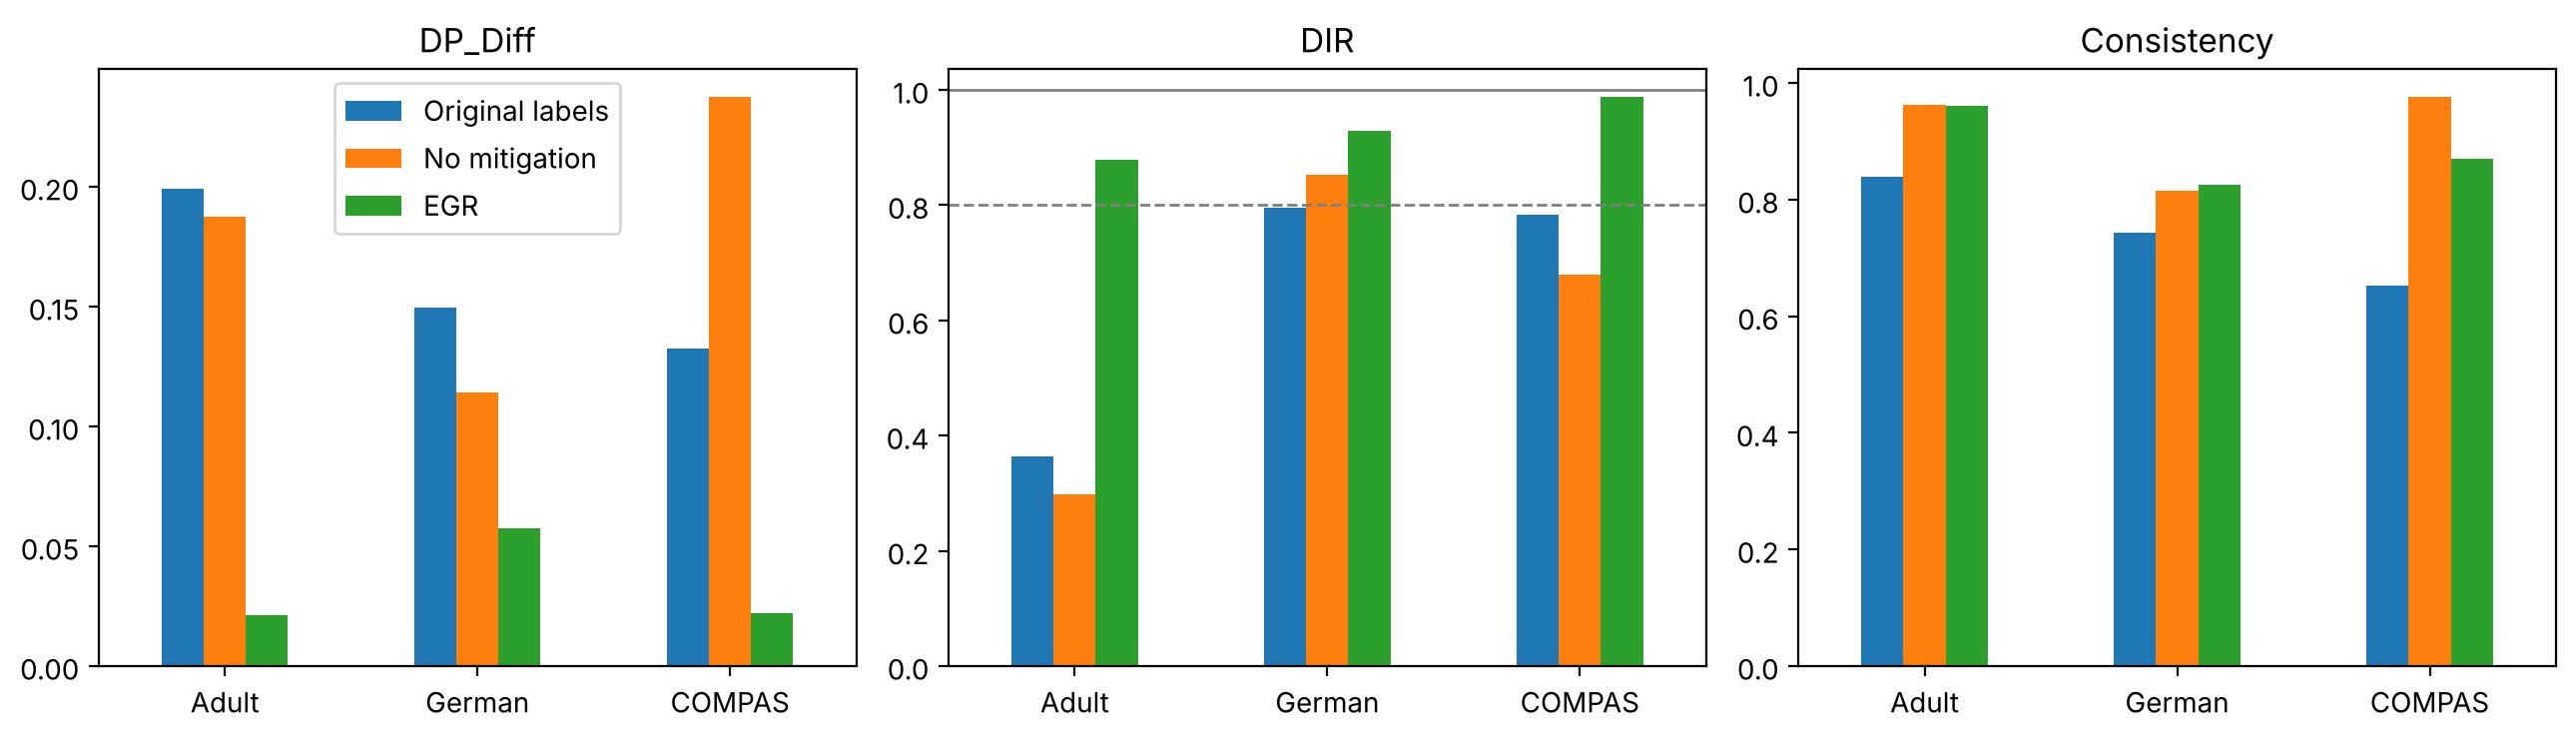

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes, ["DP_Diff", "DIR", "Consistency"]):
    table = comparison[metric].unstack()[["Original labels", "No mitigation", "EGR"]].loc[["Adult", "German", "COMPAS"]]
    table.plot.bar(ax=ax, rot=0, legend=False, title=metric)
    ax.set_xlabel("")
axes[1].axhline(0.8, color="grey", linestyle="--", linewidth=1)
axes[1].axhline(1.0, color="grey", linewidth=1)
axes[0].legend()
plt.tight_layout()
plt.show()